# Summarize frozen vs full training runs

Thin notebook wrapper around `summarize_runs.py`. Configure the run paths below, then run all
cells: the statistics table prints to the output and the two summary plots render inline.

All logic lives in `summarize_runs.py` (single source of truth, shared with the CLI script).

In [ ]:
%matplotlib inline
import summarize_runs as sr

# --- configure your runs here ---
FROZEN_PATHS = [
    '../dynapse_results/parallel_training/frozen/201285_0/',
    '../dynapse_results/parallel_training/frozen/201285_1/',
    '../dynapse_results/parallel_training/frozen/201285_2/',
    '../dynapse_results/parallel_training/frozen/201286_0/',
    '../dynapse_results/parallel_training/frozen/201286_1/',
    '../dynapse_results/parallel_training/frozen/201286_2/',
    '../dynapse_results/parallel_training/frozen/201287_0/',
    '../dynapse_results/parallel_training/frozen/201287_1/',
    '../dynapse_results/parallel_training/frozen/201287_2/',
    '../dynapse_results/parallel_training/frozen/201288_0/',
    '../dynapse_results/parallel_training/frozen/201288_1/',
    '../dynapse_results/parallel_training/frozen/201288_2/',
    '../dynapse_results/parallel_training/frozen/201289_0/',
    '../dynapse_results/parallel_training/frozen/201289_1/',
    '../dynapse_results/parallel_training/frozen/201289_2/',
]
FULL_PATHS = [
    '../dynapse_results/parallel_training/full/201285_0/',
    '../dynapse_results/parallel_training/full/201285_1/',
    '../resudynapse_resultslts/parallel_training/full/201285_2/',
    '../dynapse_results/parallel_training/full/201286_0/',
    '../dynapse_results/parallel_training/full/201286_1/',
    '../dynapse_results/parallel_training/full/201286_2/',
    '../dynapse_results/parallel_training/full/201287_0/',
    '../dynapse_results/parallel_training/full/201287_1/',
    '../dynapse_results/parallel_training/full/201287_2/',
    '../dynapse_results/parallel_training/full/201288_0/',
    '../dynapse_results/parallel_training/full/201288_1/',
    '../dynapse_results/parallel_training/full/201288_2/',
    '../dynapse_results/parallel_training/full/201289_0/',
    '../dynapse_results/parallel_training/full/201289_1/',
    '../dynapse_results/parallel_training/full/201289_2/',
]
ROLLING_WINDOW = 100  # smoothing for the training curves only


Summary: 15 frozen run(s), 15 full run(s)
Improvement pairs (exact chip+seed match): 15

Per-group statistics across runs:
                 Metric            Eval  Group  n    Mean    Std     Min     Max
Classification accuracy Best validation Frozen 15  0.6717 0.0417  0.5930  0.7410
Classification accuracy Best validation   Full 15  0.7187 0.0138  0.6950  0.7530
Classification accuracy            Test Frozen 15  0.6419 0.0387  0.5880  0.7280
Classification accuracy            Test   Full 15  0.6749 0.0282  0.6190  0.7150
      Target error [Hz] Best validation Frozen 15 11.2546 0.5322 10.4800 12.2925
      Target error [Hz] Best validation   Full 15 10.6843 0.2404 10.2572 11.1800
      Target error [Hz]            Test Frozen 15 11.3593 0.5302 10.6390 12.2473
      Target error [Hz]            Test   Full 15 10.7840 0.3620 10.3267 11.5382

Frozen -> full improvement (positive = full is better):
                 Metric            Eval  pairs Mean improvement    Std     Min    Max
    

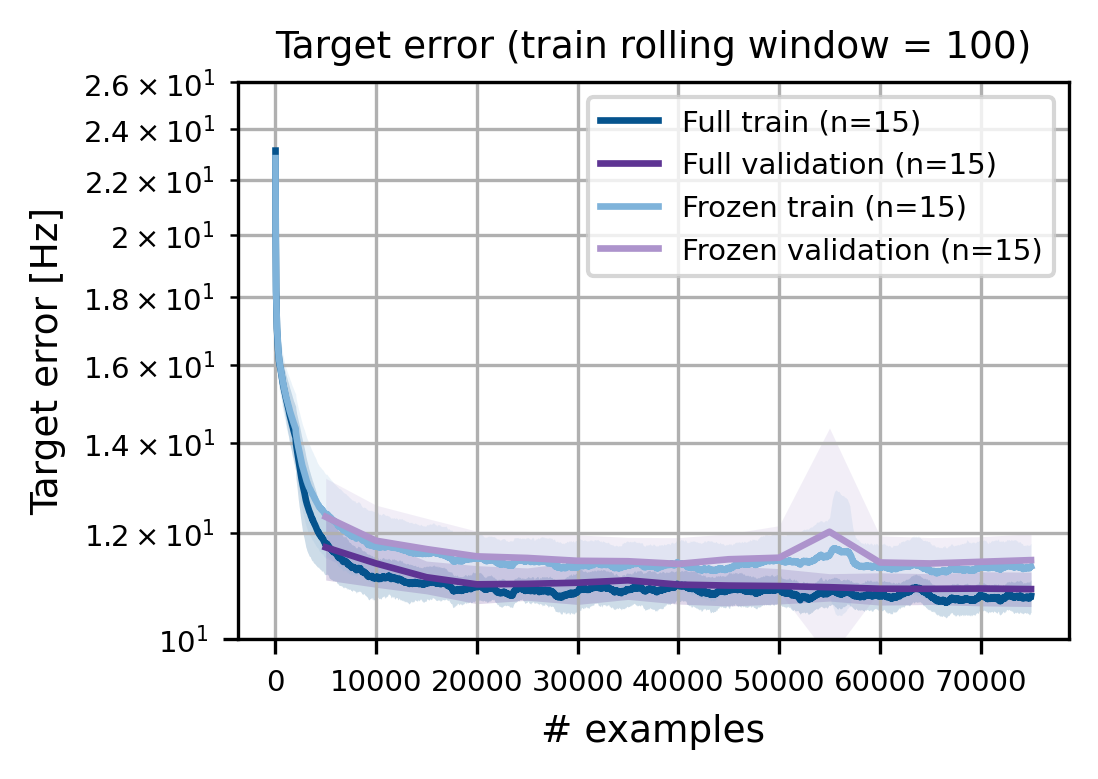

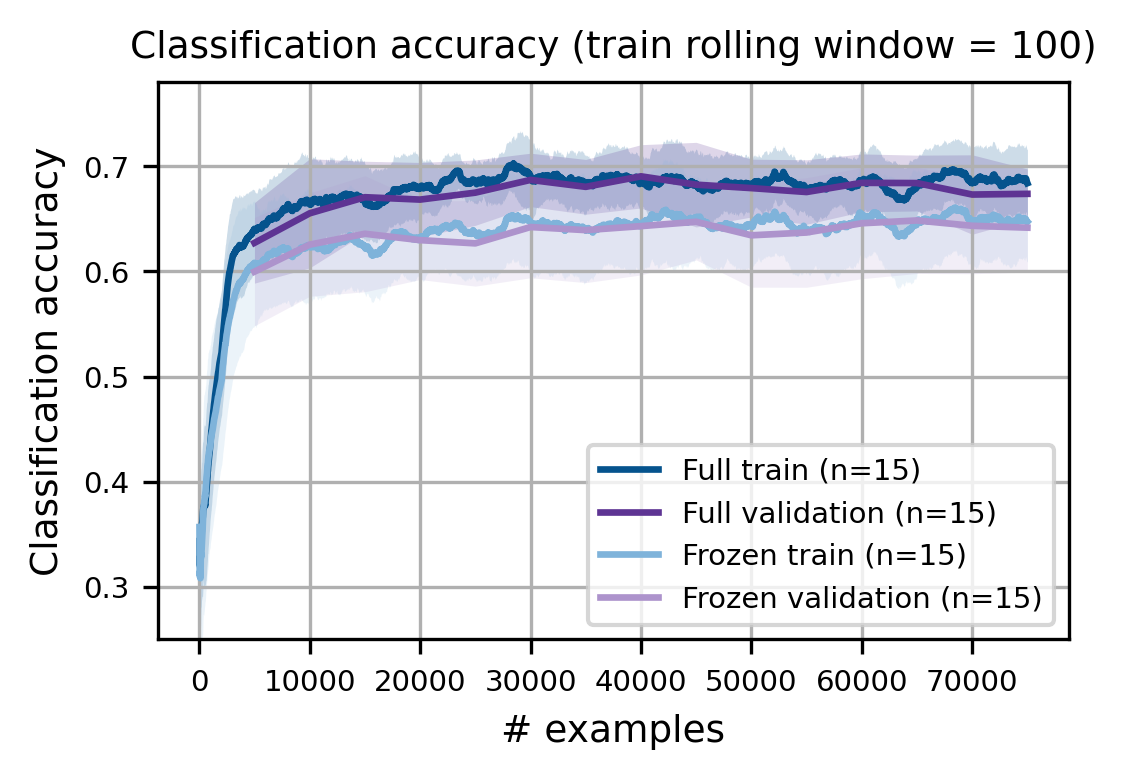

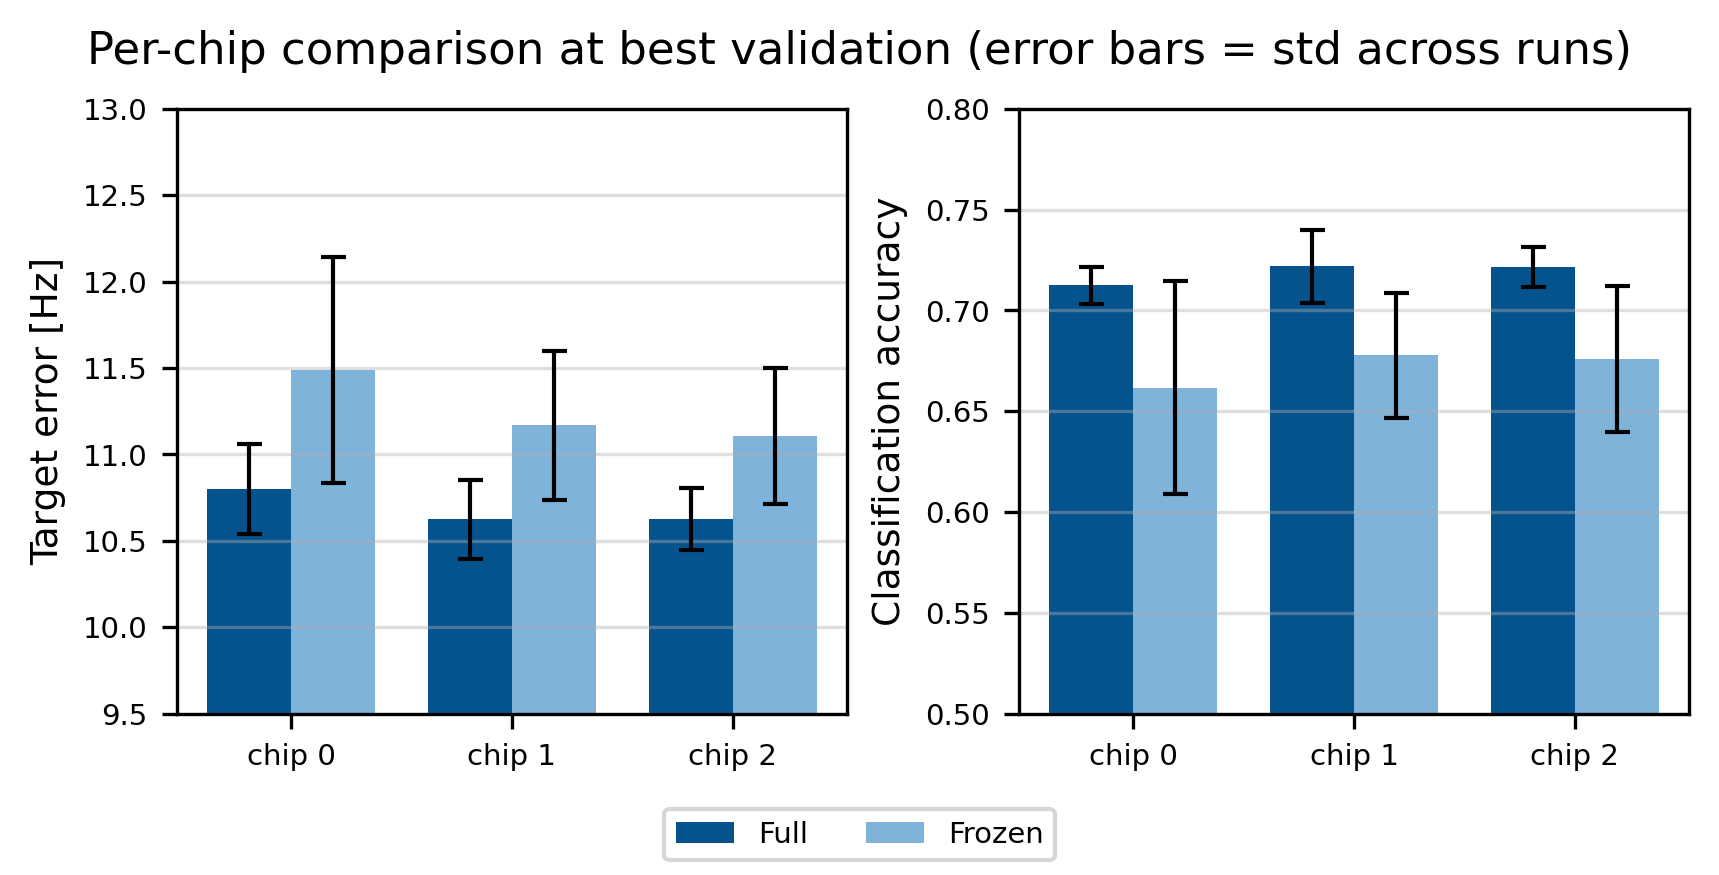

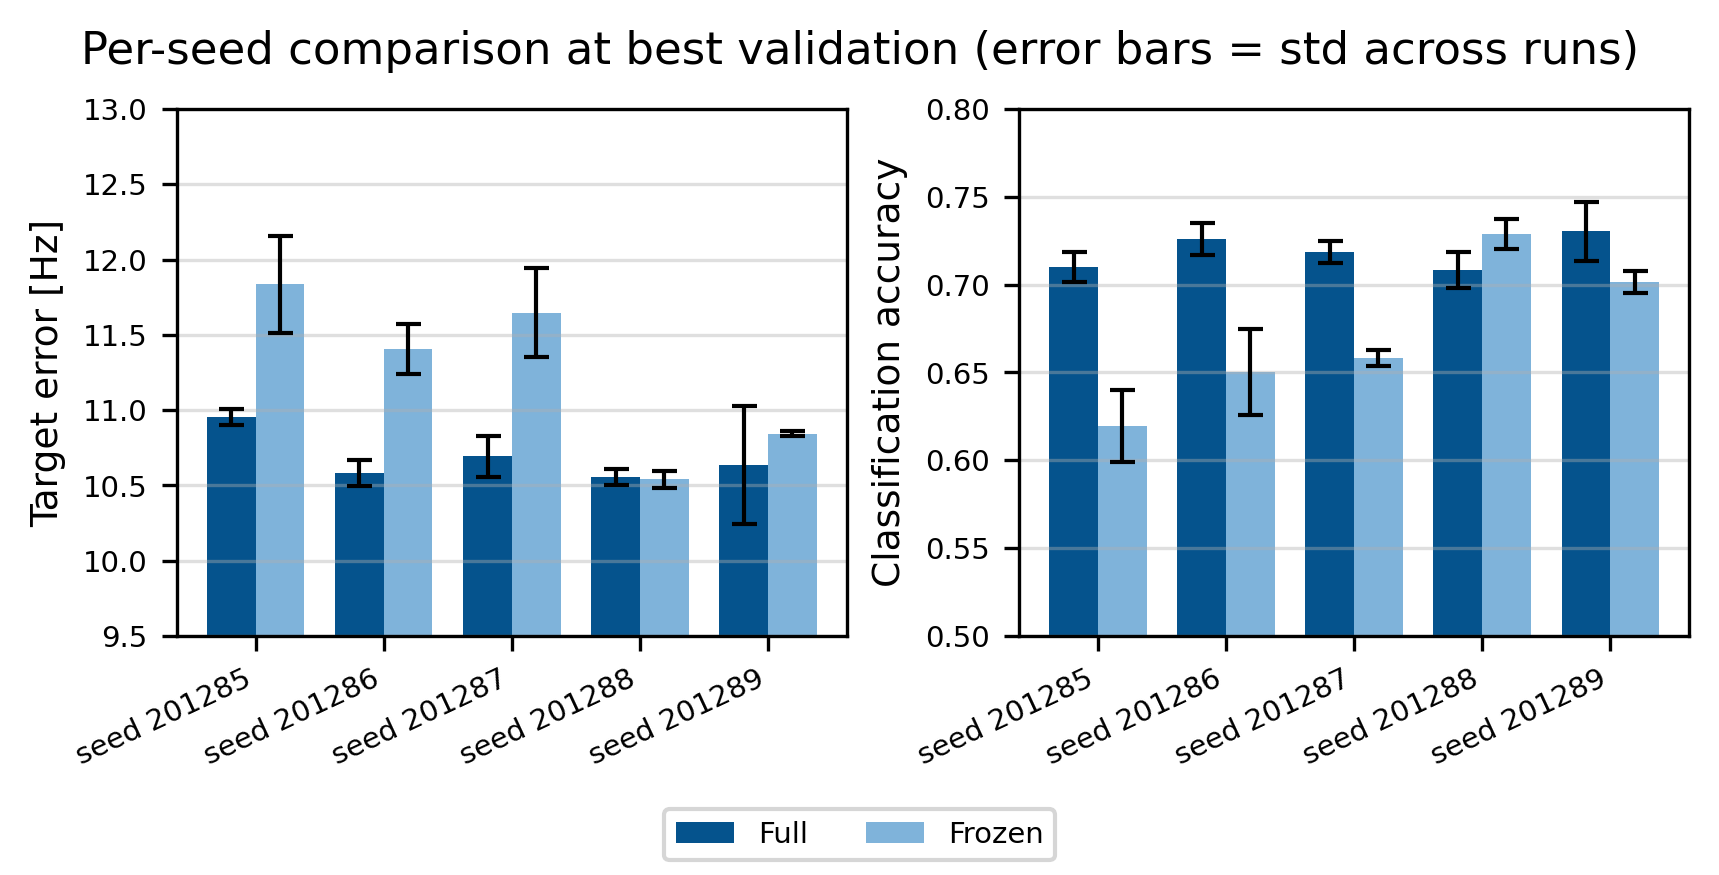

In [2]:
# Load, compute statistics, print the table, and render both plots inline.
# save=False keeps it notebook-only; set save=True to also write PDF/PNG files.
results = sr.summarize(
    sr._expand(FROZEN_PATHS),
    sr._expand(FULL_PATHS),
    rolling_window=ROLLING_WINDOW,
    save=False,
    show=True,
)

In [3]:
# The returned dict exposes everything for further analysis, e.g.:
#   results['frozen_stats'], results['full_stats'], results['improvements']
#   results['frozen_runs'][0]  # per-run curves and scalars
import pandas as pd
pd.DataFrame(results['improvements']['pairs'], columns=['chip', 'seed'])

,chip,seed
0,0,201285
1,0,201286
2,0,201287
3,0,201288
4,0,201289
5,1,201285
6,1,201286
7,1,201287
8,1,201288
9,1,201289
